# Phase 4 — aggregate measured results

Measured run: v5. Prepared correction: v6, not run. Core engineering checks passed; v5 stopping flags are invalid. No baseline CER or fine-tuning has run.

See [the complete results report](../docs/PHASE4_RESULTS.md). Private prediction and transcript outputs are omitted from this public report; original artifacts are preserved locally.


## Measured results

| Check | Result |
|---|---|
| Model and processor | neurlang/ipa-whisper-base, revision 949f7c4e4ee374b5202bc5886f6e4552e5ae2371 |
| Frozen targets | 5,044; zero round-trip, unknown-token or target-length failures |
| Set-aside references | 42; all representable, still excluded pending label review |
| Maximum reference content tokens | Frozen 358; set-aside 361; special-token-inclusive checks pass capacity 448 |
| Audio/features | 12 training-only clips, 0.75–28.82 s; finite [1,80,3000] features |
| Repeat generation/save-reload | First clip token IDs identical in both checks |
| Compute | Tesla T4; FP32; greedy batch 1; seed 0; Transformers 4.57.1; PyTorch 2.11.0+cu128 |
| Generation-loop time | 18.8245 s for 128.2169 s audio; includes repeated first inference, processing and incremental exports |
| Peak PyTorch allocated/reserved | 339.26 / 362 MiB; excludes save/reload and does not measure training memory |
| Accuracy | Not scored; poor qualitative alignment and extended repetition |

All 12 decoded predictions match the earlier mixed-version run. Tokenizer representability is not evidence of acoustic recognition competence. Set-aside labels are not reinstated by passing tokenizer checks. Repeatability here concerns one clip on one runtime. The overall Kaggle environment still has recorded dependency conflicts for unrelated installed applications; this does not claim a globally clean environment.



## Training-only durations and latency

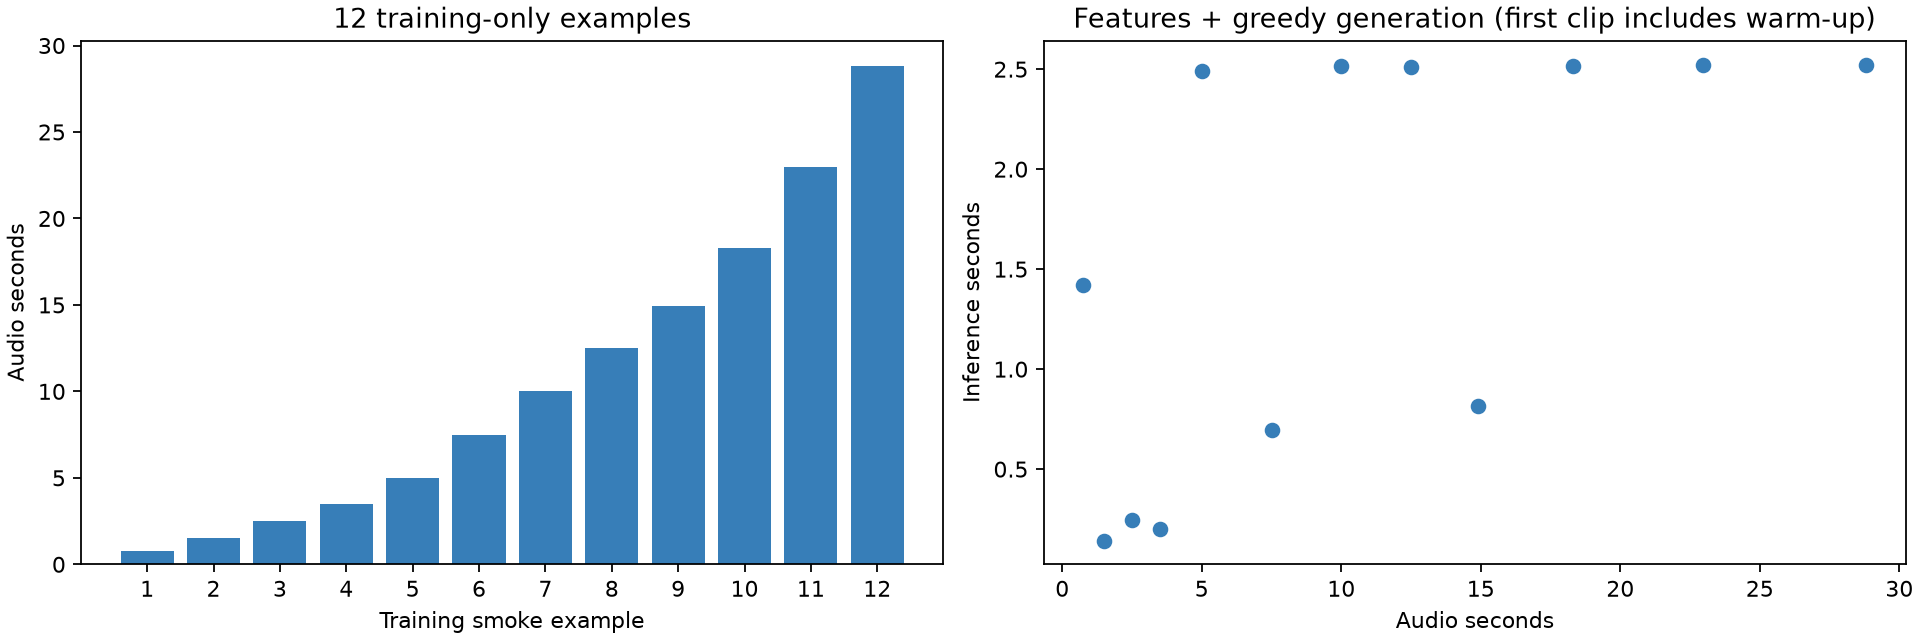

## Content token lengths and repetition; prefix/EOS excluded

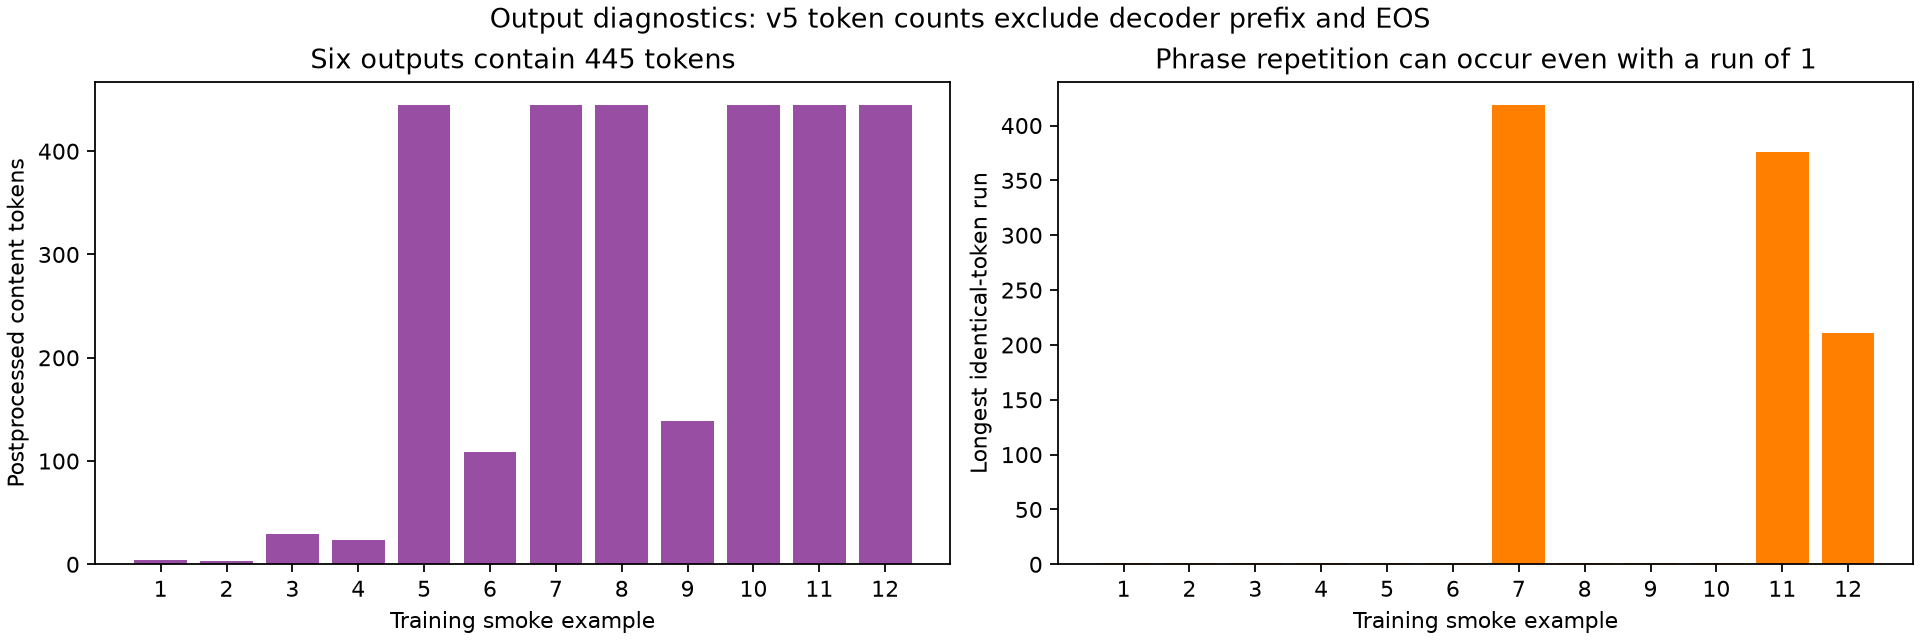

## Inference memory, not training memory

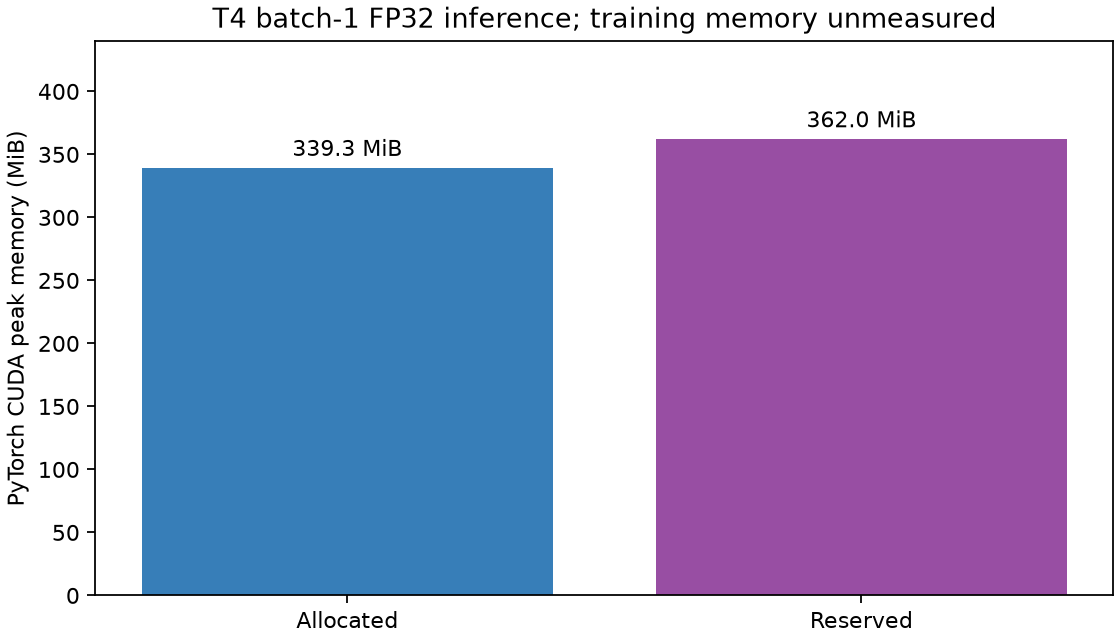

## Stopping diagnostic correction

Whisper v4.57.1's default returned tensor excludes decoder input tokens and EOS. Therefore the earlier plot's zero EOS endings and zero cap hits cannot be interpreted as generation termination results. Six 445-content-token outputs strongly suggest the 448-token limit was reached with a three-token prefix, but full decoder sequences must confirm it. One output contains U+FFFD; preserve it in scoring and inspect its raw termination.

The v6 source requests `return_dict_in_generate=True` and reads `.sequences` for short-form generation, which the pinned implementation documents as retaining decoder prefix and EOS. This instrumentation route still needs a small equivalence/termination check on the same training examples before baseline use. [Pinned Transformers implementation](https://github.com/huggingface/transformers/blob/v4.57.1/src/transformers/models/whisper/generation_whisper.py).

## Next steps

1. Run the corrected stopping instrumentation on the same training examples, verify decoded text against v5 and regenerate EOS/cap plots. Keep poor predictions and the original run evidence.
2. Verify CER on known pairs, combining marks and empty predictions. Keep NFD + trim + repeated ordinary-space collapse; retain spaces and IPA marks.
3. Prepare/hash-check the frozen validation bundle: 732 clips / 1.881808 hours. Run a small preflight, then all validation clips with resumable outputs and corpus code-point CER, S/D/I, reference characters, failures, cap hits and timing. No test-driven tuning.
4. Conduct a 1–2 hour supervised training pilot; select by validation CER and measure training memory before expanding. Reserve the 683 test clips for final evaluation.

The Phase 3.5B split was accepted and frozen locally on 1 November 2026: train 3,629 / 10.851637 h, validation 732 / 1.881808 h, test 683 / 1.891057 h. Manifests remain private. No new split or linguistic normalization is justified by this smoke run.
